In [757]:
import numpy as np              # Одномерные и многомерные массивы (array)
import pandas as pd             # Таблицы и временные ряды (dataframe, series)
import matplotlib.pyplot as plt # Научная графика
import seaborn as sns           # Еще больше красивой графики для визуализации данных
import sklearn                  # Алгоритмы машинного обучения

#0. Загрузка датасета и постановка задачи

## Загружаем датасет и смотрим его структуру


In [758]:
 data_raw = pd.read_csv('anime-dataset-2023.csv')

In [759]:
#смотрим размер датасета
data_raw.shape

(24905, 24)

In [760]:
data_raw

,anime_id,Name,English name,Other name,Score,Genres,Synopsis,Type,Episodes,Aired,...,Studios,Source,Duration,Rating,Rank,Popularity,Favorites,Scored By,Members,Image URL
0,1,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,8.75,"Action, Award Winning, Sci-Fi","Crime is timeless. By the year 2071, humanity ...",TV,26.0,"Apr 3, 1998 to Apr 24, 1999",...,Sunrise,Original,24 min per ep,R - 17+ (violence & profanity),41.0,43,78525,914193.0,1771505,https://cdn.myanimelist.net/images/anime/4/196...
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,カウボーイビバップ 天国の扉,8.38,"Action, Sci-Fi","Another day, another bounty—such is the life o...",Movie,1.0,"Sep 1, 2001",...,Bones,Original,1 hr 55 min,R - 17+ (violence & profanity),189.0,602,1448,206248.0,360978,https://cdn.myanimelist.net/images/anime/1439/...
2,6,Trigun,Trigun,トライガン,8.22,"Action, Adventure, Sci-Fi","Vash the Stampede is the man with a $$60,000,0...",TV,26.0,"Apr 1, 1998 to Sep 30, 1998",...,Madhouse,Manga,24 min per ep,PG-13 - Teens 13 or older,328.0,246,15035,356739.0,727252,https://cdn.myanimelist.net/images/anime/7/203...
3,7,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),7.25,"Action, Drama, Mystery, Supernatural",Robin Sena is a powerful craft user drafted in...,TV,26.0,"Jul 3, 2002 to Dec 25, 2002",...,Sunrise,Original,25 min per ep,PG-13 - Teens 13 or older,2764.0,1795,613,42829.0,111931,https://cdn.myanimelist.net/images/anime/10/19...
4,8,Bouken Ou Beet,Beet the Vandel Buster,冒険王ビィト,6.94,"Adventure, Fantasy, Supernatural",It is the dark century and the people are suff...,TV,52.0,"Sep 30, 2004 to Sep 29, 2005",...,Toei Animation,Manga,23 min per ep,PG - Children,4240.0,5126,14,6413.0,15001,https://cdn.myanimelist.net/images/anime/7/215...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24900,55731,Wu Nao Monu,UNKNOWN,无脑魔女,UNKNOWN,"Comedy, Fantasy, Slice of Life",No description available for this anime.,ONA,15.0,"Jul 4, 2023 to ?",...,UNKNOWN,Web manga,Unknown,PG-13 - Teens 13 or older,UNKNOWN,24723,0,UNKNOWN,0,https://cdn.myanimelist.net/images/anime/1386/...
24901,55732,Bu Xing Si: Yuan Qi,Blader Soul,捕星司·源起,UNKNOWN,"Action, Adventure, Fantasy",No description available for this anime.,ONA,18.0,"Jul 27, 2023 to ?",...,UNKNOWN,Web novel,Unknown,PG-13 - Teens 13 or older,0.0,0,0,UNKNOWN,0,https://cdn.myanimelist.net/images/anime/1383/...
24902,55733,Di Yi Xulie,The First Order,第一序列,UNKNOWN,"Action, Adventure, Fantasy, Sci-Fi",No description available for this anime.,ONA,16.0,"Jul 19, 2023 to ?",...,UNKNOWN,Web novel,Unknown,PG-13 - Teens 13 or older,0.0,0,0,UNKNOWN,0,https://cdn.myanimelist.net/images/anime/1130/...
24903,55734,Bokura no Saishuu Sensou,UNKNOWN,僕らの最終戦争,UNKNOWN,UNKNOWN,A music video for the song Bokura no Saishuu S...,Music,1.0,"Apr 23, 2022",...,UNKNOWN,Original,3 min,PG-13 - Teens 13 or older,0.0,0,0,UNKNOWN,0,https://cdn.myanimelist.net/images/anime/1931/...


In [761]:
#пример 5 значений из датасета
data_raw.sample(5)

,anime_id,Name,English name,Other name,Score,Genres,Synopsis,Type,Episodes,Aired,...,Studios,Source,Duration,Rating,Rank,Popularity,Favorites,Scored By,Members,Image URL
23017,52758,Konayuki,UNKNOWN,粉雪,UNKNOWN,UNKNOWN,"Music video for the song Konayuki, performed b...",Music,1.0,"Feb 11, 2021",...,Pie in the sky,Original,5 min,G - All Ages,UNKNOWN,20448,0,UNKNOWN,108,https://cdn.myanimelist.net/images/anime/1537/...
7597,17245,Christmas,UNKNOWN,クリスマス,5.39,Supernatural,A girl creates a talisman and makes a wish for...,Music,1.0,"Nov 16, 2010",...,UNKNOWN,Unknown,6 min,G - All Ages,UNKNOWN,12744,1,537.0,968,https://cdn.myanimelist.net/images/anime/3/460...
1605,1766,Youseiki Suikoden,Suikoden Demon Century,妖世紀水滸伝,5.65,"Action, Fantasy","In the early 21st century, an earthquake destr...",OVA,1.0,"Sep 25, 1993",...,J.C.Staff,Light novel,45 min,R - 17+ (violence & profanity),10276.0,9436,3,1183.0,3044,https://cdn.myanimelist.net/images/anime/5/465...
4268,5687,Doura,UNKNOWN,瞳裸,4.67,Hentai,No description available for this anime.,OVA,4.0,"Jun 18, 2001 to Jan 18, 2002",...,Meltdown,Visual novel,28 min per ep,Rx - Hentai,UNKNOWN,12419,1,271.0,1067,https://cdn.myanimelist.net/images/anime/8/118...
10275,30055,Mabeob Chunjamun: Daemawang-ui Buhwal-eul Mag-ala,UNKNOWN,마법천자문: 대마왕의 부활을 막아라,UNKNOWN,UNKNOWN,No description available for this anime.,Movie,1.0,2010,...,UNKNOWN,Unknown,1 hr 25 min,G - All Ages,17811.0,19537,0,UNKNOWN,161,https://cdn.myanimelist.net/images/anime/7/719...


In [762]:
#информация о датасете
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24905 entries, 0 to 24904
Data columns (total 24 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   anime_id      24905 non-null  int64 
 1   Name          24905 non-null  object
 2   English name  24905 non-null  object
 3   Other name    24905 non-null  object
 4   Score         24905 non-null  object
 5   Genres        24905 non-null  object
 6   Synopsis      24905 non-null  object
 7   Type          24905 non-null  object
 8   Episodes      24905 non-null  object
 9   Aired         24905 non-null  object
 10  Premiered     24905 non-null  object
 11  Status        24905 non-null  object
 12  Producers     24905 non-null  object
 13  Licensors     24905 non-null  object
 14  Studios       24905 non-null  object
 15  Source        24905 non-null  object
 16  Duration      24905 non-null  object
 17  Rating        24905 non-null  object
 18  Rank          24905 non-null  object
 19  Popu

Проанализировав датасет, было принято решение предсказывать среднюю оценку аниме `Score` на основе характеристик, которые известны до его выхода:

- `Genres` — жанры аниме
- `Type` — тип выхода (TV, Movie, OVA)
- `Episodes` — количество эпизодов
- `Aired` — год выхода и сезон (извлечем из даты)
- `Premiered` — сезон выхода (весна, лето, осень, зима)
- `Producers` — продюсеры
- `Studios` — студия-производитель
- `Source` — первоисточник (манга, ранобэ, оригинал)
- `Duration` — длительность эпизода
- `Rating` — возрастной рейтинг

Цель - Понять, какие характеристики влияют на оценку зрителей, чтобы оценить целесообразность производства

Что мы не используем -
- `Members`, `Popularity`, `Favorites`, `Scored By`, `Rank` — эти метрики формируются после выхода аниме, их использование приведет к утечке данных
- `Name`, `Synopsis` — текстовые признаки, требуют нейросетевой обработки
- `Status` не имеет практической пользы, поскольку это текущее состояние аниме, оно либо в процессе выхода, либо вышло, либо анонсировано
- `Licensors` - они выбираются уже после того, как аниме вышло, например, дял проката в других странах

#1. Обработка датасета

## Удаляем лишние столбцы

In [763]:
columns_to_drop = ['anime_id', 'Name', 'English name', 'Other name', 'Image URL', 'Synopsis',
                   'Rank', 'Popularity', 'Favorites', 'Scored By', 'Members', 'Status', 'Licensors']
data_raw = data_raw.drop(columns=columns_to_drop)

In [764]:
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24905 entries, 0 to 24904
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Score      24905 non-null  object
 1   Genres     24905 non-null  object
 2   Type       24905 non-null  object
 3   Episodes   24905 non-null  object
 4   Aired      24905 non-null  object
 5   Premiered  24905 non-null  object
 6   Producers  24905 non-null  object
 7   Studios    24905 non-null  object
 8   Source     24905 non-null  object
 9   Duration   24905 non-null  object
 10  Rating     24905 non-null  object
dtypes: object(11)
memory usage: 2.1+ MB


In [765]:
data_raw.sample(5)

,Score,Genres,Type,Episodes,Aired,Premiered,Producers,Studios,Source,Duration,Rating
7923,4.99,Sci-Fi,OVA,1.0,"Sep 25, 1992",UNKNOWN,Victor Entertainment,UNKNOWN,Original,32 min,PG-13 - Teens 13 or older
3282,6.69,"Drama, Romance",TV,20.0,"Apr 8, 1985 to Oct 5, 1985",spring 1985,UNKNOWN,Tatsunoko Production,Manga,22 min per ep,PG-13 - Teens 13 or older
3386,5.25,Hentai,OVA,2.0,"Feb 14, 1997 to Jan 23, 1998",UNKNOWN,Knack Productions,UNKNOWN,Unknown,38 min per ep,Rx - Hentai
6569,4.19,"Fantasy, Horror",ONA,1.0,"Dec 8, 2008",UNKNOWN,UNKNOWN,UNKNOWN,Original,5 min,R - 17+ (violence & profanity)
14454,UNKNOWN,UNKNOWN,Music,5.0,"Sep 20, 2008 to Dec 31, 2009",UNKNOWN,UNKNOWN,UNKNOWN,Original,30 min per ep,G - All Ages


##в `Premiered` слишком много пропусков (около 80%), поэтому создадим и заполним столбец `season` с сезоном выхода, исходя из `Aired`

In [766]:
# Словарь для сокращений месяцев в сезоны
month_to_season = {
    'Jan': 'Winter', 'Feb': 'Winter', 'Dec': 'Winter',
    'Mar': 'Spring', 'Apr': 'Spring', 'May': 'Spring',
    'Jun': 'Summer', 'Jul': 'Summer', 'Aug': 'Summer',
    'Sep': 'Fall', 'Oct': 'Fall', 'Nov': 'Fall'
}

# Функция для извлечения сезона
def get_season_from_aired(value):
    if pd.isna(value) or str(value).strip().lower() in ['unknown', 'not available', '']:
        return np.nan

    try:
        first_word = str(value).strip().split()[0].capitalize()
        return month_to_season.get(first_word, np.nan)
    except:
        return np.nan

# Создаем новый столбец Season
data_raw['Season'] = data_raw['Aired'].apply(get_season_from_aired)

# Удаляем исходные столбцы, так как они больше не нужны
data_raw = data_raw.drop(columns=['Premiered', 'Aired'])

# Преобразуем новый столбец в категориальный тип
data_raw['Season'] = data_raw['Season'].astype('category')

In [767]:
data_raw.sample(15)

,Score,Genres,Type,Episodes,Producers,Studios,Source,Duration,Rating,Season
18431,UNKNOWN,"Adventure, Fantasy",Movie,1.0,UNKNOWN,UNKNOWN,Unknown,1 hr 12 min,PG - Children,Fall
1693,6.81,"Drama, Sci-Fi",Special,2.0,Tohokushinsha Film Corporation,Madhouse,Manga,1 hr 17 min per ep,R - 17+ (violence & profanity),Fall
11009,6.25,"Action, Fantasy, Supernatural",Special,1.0,Atlus,Satelight,Game,5 min,PG-13 - Teens 13 or older,Summer
2988,5.5,Hentai,OVA,3.0,Milky Animation Label,Studio Jam,Visual novel,28 min per ep,Rx - Hentai,Winter
13225,6.9,Action,Movie,2.0,Magic Capsule,Bibury Animation Studios,Visual novel,49 min per ep,R - 17+ (violence & profanity),Spring
14328,UNKNOWN,UNKNOWN,Music,1.0,Avex Entertainment,UNKNOWN,Original,2 min,G - All Ages,Spring
2696,7.65,"Comedy, Slice of Life",TV,13.0,"Starchild Records, Magic Capsule, Eye Move, Su...",Daume,Manga,24 min per ep,PG-13 - Teens 13 or older,Fall
17769,UNKNOWN,Fantasy,Movie,1.0,UNKNOWN,Shanghai Animation Film Studio,Other,1 hr 39 min,G - All Ages,Summer
14567,5.63,UNKNOWN,Special,1.0,UNKNOWN,UNKNOWN,Picture book,3 min,G - All Ages,Winter
8769,6.3,Hentai,OVA,1.0,Pink Pineapple,Office Takeout,Visual novel,28 min,Rx - Hentai,Spring


In [768]:
# Выводим статистику для проверки
print("Распределение сезонов:")
print(data_raw['Season'].value_counts(dropna=False))

nan_count = data_raw['Season'].isna().sum()
print(f"\nОсталось пропусков (NaN) в столбце Season: {nan_count} ({nan_count / len(data_raw) * 100:.1f}%)")

Распределение сезонов:
Season
Spring    5645
Summer    5151
Fall      5069
Winter    4885
NaN       4155
Name: count, dtype: int64

Осталось пропусков (NaN) в столбце Season: 4155 (16.7%)


Заполним NaN отдельной новой категорией Unknown

In [769]:
# Добавляем новую категорию 'Unknown' в наш категориальный столбец
data_raw['Season'] = data_raw['Season'].cat.add_categories('Unknown')

# Заполняем все пропуски (NaN) этим новым значением
data_raw['Season'] = data_raw['Season'].fillna('Unknown')

## Теперь проанализируем такие признаки, как `Producers`, `Studios`
Их объединяет следующее - более 40% пропусков, много маленьких уникальных значений (множество мелких студий), а так же то, что их можно разделить на "опытные" и "неопытные", по количеству выпущенных аниме. Будем предполагать, что если продюсер/студия имеют значение Unknown(то есть пропуск), то они либо малоизвестны и поэтому их название не занесли, либо они уже не работают в этой сфере (в обоих случаях их опыт не является тем, на который мы можем положиться или воспользоваться им)

Над некоторыми проектами работало сразу несколько студий, поэтому с помощью .explode() разобьем их на различные строки

Всего уникальных известных студий в датасете: 1043
Студий, выпустивших ровно 1 аниме: 310


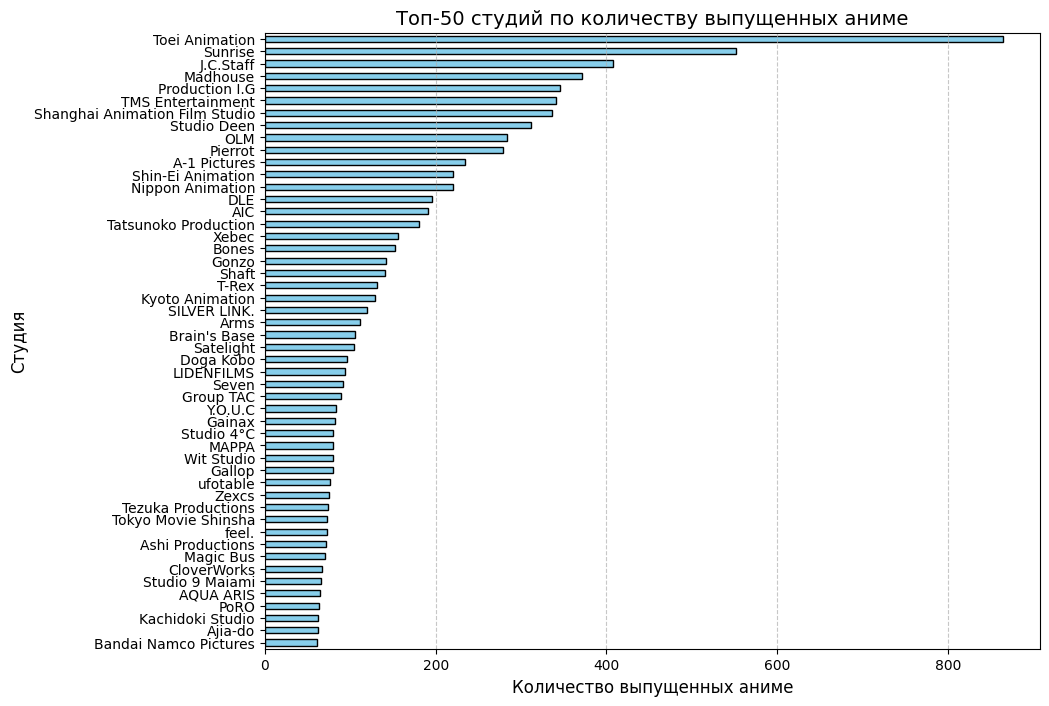

In [770]:
# Разделяем по запятой, "взрываем" в отдельные строки и убираем пробелы по краям
studios_exploded = data_raw['Studios'].str.split(',').explode().str.strip()

# ФИЛЬТРАЦИЯ: Оставляем только реальные названия студий
# Исключаем 'UNKNOWN', 'Unknown', 'None' и пустые строки
valid_studios = studios_exploded[~studios_exploded.isin(['UNKNOWN', 'Unknown', 'None', ''])]

# Считаем количество аниме только для валидных студий
studio_counts = valid_studios.value_counts()

print(f"Всего уникальных известных студий в датасете: {len(studio_counts)}")
print(f"Студий, выпустивших ровно 1 аниме: {(studio_counts == 1).sum()}")

# Визуализируем топ-50 студий
plt.figure(figsize=(10, 8))
studio_counts.head(50).plot(kind='barh', color='skyblue', edgecolor='black')

plt.title('Топ-50 студий по количеству выпущенных аниме', fontsize=14)
plt.xlabel('Количество выпущенных аниме', fontsize=12)
plt.ylabel('Студия', fontsize=12)

plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Студии, которые создали более 400 аниме считать выбросами не совсем корректно, т.к. в нашей задаче они являются теми, кто зачастую гарантирует качество анимаций и визуала

In [771]:
studio_counts.quantile([0.005,.01,.05,.1,.5,.9,.95,.99,.995])

,count
0.005,1.00
0.010,1.00
0.050,1.00
0.100,1.00
0.500,3.00
0.900,30.00
0.950,58.90
0.990,228.12
0.995,339.95


Выберем 0.9 перцентиль для разделения на популярные и непопулярные студии и проверим соотношение классов

In [772]:
# Задаём порог, опираясь на значения из перцентилей
threshold = 30

# Создаём множество "опытных" студий
experienced_studios = set()
for studio, count in studio_counts.items():
    if count >= threshold:
        experienced_studios.add(studio)

print(f"Количество опытных студий (>= {threshold} аниме): {len(experienced_studios)}")

def check_experienced(studios_str):
    # Проверяем на пропуск или 'UNKNOWN'
    if pd.isna(studios_str) or studios_str.strip().lower() in ['unknown', 'none', '']:
        return 0

    # Разбиваем строку по запятой и убираем пробелы
    studios_list = [s.strip() for s in studios_str.split(',')]

    # Проверяем, есть ли хотя бы одна опытная студия
    for studio in studios_list:
        if studio in experienced_studios:
            return 1
    return 0

# Применяем функцию к каждой строке
data_raw['Studio_Experienced'] = data_raw['Studios'].apply(check_experienced)

# Смотрим результат
print("\nРаспределение нового признака:")
print(data_raw['Studio_Experienced'].value_counts())

Количество опытных студий (>= 30 аниме): 106

Распределение нового признака:
Studio_Experienced
0    14425
1    10480
Name: count, dtype: int64


Мы получили хорошее соотношение классов, с которым можно работать. Теперь удалим старый столбец и проделаем то же самое для продюсеров

In [773]:
data_raw = data_raw.drop(columns=['Studios'])

Всего уникальных известных продюсеров в датасете: 1548
Продюсеров, выпустивших ровно 1 аниме: 489


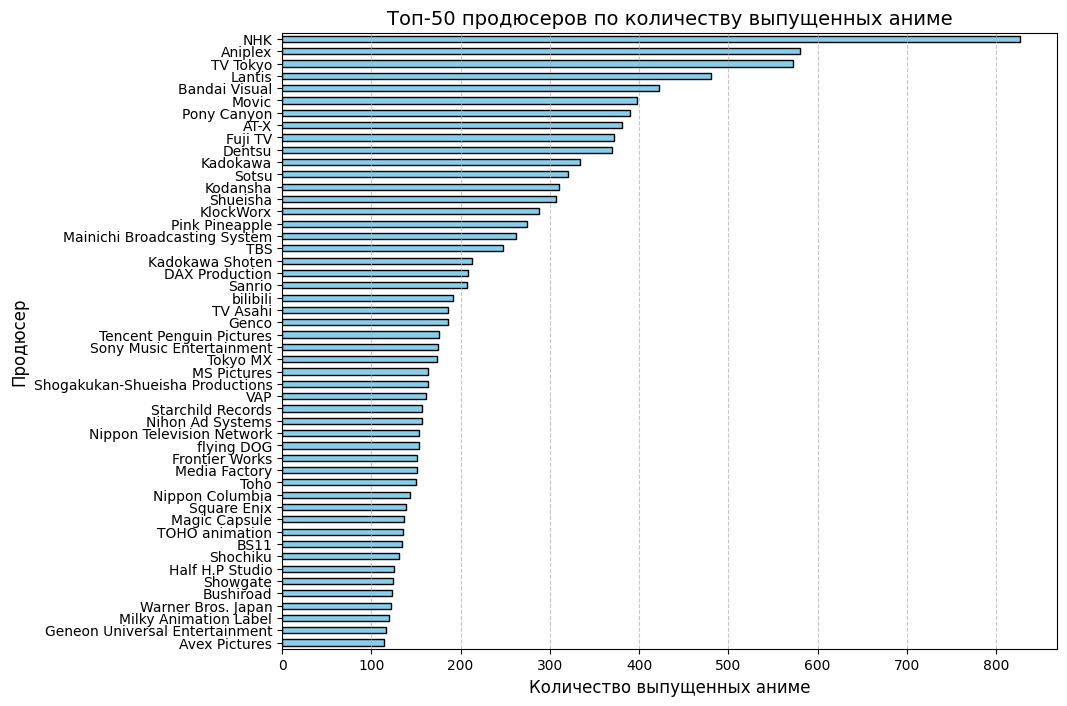

In [774]:
# Разделяем по запятой, "взрываем" в отдельные строки и убираем пробелы по краям
Producers_exploded = data_raw['Producers'].str.split(',').explode().str.strip()

# ФИЛЬТРАЦИЯ: Оставляем только реальные названия продюсеров
# Исключаем 'UNKNOWN', 'Unknown', 'None' и пустые строки
valid_Producers = Producers_exploded[~Producers_exploded.isin(['UNKNOWN', 'Unknown', 'None', ''])]

# Считаем количество аниме только для валидных продюсеров
producers_counts = valid_Producers.value_counts()

print(f"Всего уникальных известных продюсеров в датасете: {len(producers_counts)}")
print(f"Продюсеров, выпустивших ровно 1 аниме: {(producers_counts == 1).sum()}")

# Визуализируем топ-50 Продюсеров
plt.figure(figsize=(10, 8))
producers_counts.head(50).plot(kind='barh', color='skyblue', edgecolor='black')

plt.title('Топ-50 продюсеров по количеству выпущенных аниме', fontsize=14)
plt.xlabel('Количество выпущенных аниме', fontsize=12)
plt.ylabel('Продюсер', fontsize=12)

plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [775]:
producers_counts.quantile([0.005,.01,.05,.1,.5,.9,.95,.99,.995])

,count
0.005,1.000
0.010,1.000
0.050,1.000
0.100,1.000
0.500,3.000
0.900,30.300
0.950,76.650
0.990,268.360
0.995,374.385


In [776]:
# Задаём порог, опираясь на значения из перцентилей
threshold = 20

# Создаём множество "опытных" продюсеров
experienced_producers = set()
for producers, count in producers_counts.items():
    if count >= threshold:
        experienced_producers.add(producers)

print(f"Количество опытных продюсеров (>= {threshold} аниме): {len(experienced_producers)}")

def check_experienced(producers_str):
    # Проверяем на пропуск или 'UNKNOWN'
    if pd.isna(producers_str) or producers_str.strip().lower() in ['unknown', 'none', '']:
        return 0

    # Разбиваем строку по запятой и убираем пробелы
    producers_list = [s.strip() for s in producers_str.split(',')]

    # Проверяем, есть ли хотя бы один опытный продюсер
    for studio in producers_list:
        if studio in experienced_producers:
            return 1
    return 0

# Применяем функцию к каждой строке
data_raw['Producers_Experienced'] = data_raw['Producers'].apply(check_experienced)

# Смотрим результат
print("\nРаспределение нового признака:")
print(data_raw['Producers_Experienced'].value_counts())

Количество опытных продюсеров (>= 20 аниме): 221

Распределение нового признака:
Producers_Experienced
0    15072
1     9833
Name: count, dtype: int64


In [777]:
data_raw = data_raw.drop(columns=['Producers'])

##Обработка времени

In [778]:
import re
import numpy as np

def parse_duration(duration_str):
    # Проверка на пропуск или невалидное значение
    if pd.isna(duration_str) or str(duration_str).strip().lower() in ['unknown', 'none', '']:
        return np.nan

    duration_str = str(duration_str).lower()

    # Ищем часы (число перед "hr")
    hours_match = re.search(r'(\d+)\s*hr', duration_str)
    hours = int(hours_match.group(1)) if hours_match else 0

    # Ищем минуты (число перед "min")
    mins_match = re.search(r'(\d+)\s*min', duration_str)
    mins = int(mins_match.group(1)) if mins_match else 0

    # Если не нашли ни часов, ни минут — пробуем просто найти любое число
    # (на случай, если формат нестандартный, например просто "24")
    if hours == 0 and mins == 0:
        numbers = re.findall(r'\d+', duration_str)
        if numbers:
            return int(numbers[0])
        return np.nan

    return hours * 60 + mins

# Применяем функцию
data_raw['Duration_Minutes'] = data_raw['Duration'].apply(parse_duration)

In [779]:
# Удаляем исходный столбец
data_raw = data_raw.drop(columns=['Duration'])

In [780]:
data_raw['Duration_Minutes'].describe()

,Duration_Minutes
count,24242.000000
mean,22.916880
std,27.492824
min,1.000000
25%,5.000000
50%,19.000000
75%,25.000000
max,1500.000000


In [781]:
data_raw_sorted = data_raw.sort_values('Duration_Minutes')
data_raw_sorted['Duration_Minutes'].head(100)

,Duration_Minutes
4321,1.0
4305,1.0
4307,1.0
10439,1.0
13864,1.0
...,...
13621,1.0
21072,1.0
13582,1.0
7888,1.0


<Axes: >

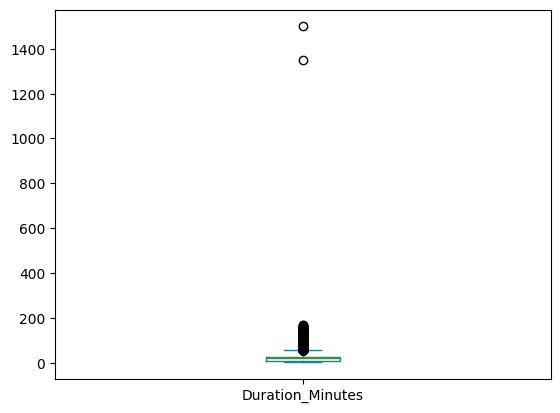

In [782]:
data_raw['Duration_Minutes'].plot(kind='box')

In [783]:
data_raw['Duration_Minutes'].quantile([.01,.05,.1,.5,.9,.95,.99,.999])

,Duration_Minutes
0.010,1.00
0.050,2.00
0.100,2.00
0.500,19.00
0.900,52.00
0.950,85.00
0.990,110.59
0.999,136.00


In [784]:
data_raw_sorted = data_raw.sort_values('Duration_Minutes', ascending=False)
print("Топ-10 самых длинных аниме:")
print(data_raw_sorted.head(10)[['Score', 'Type', 'Duration_Minutes']])

Топ-10 самых длинных аниме:
         Score     Type  Duration_Minutes
24801  UNKNOWN       TV            1500.0
24501  UNKNOWN      ONA            1351.0
7220      8.22    Movie             168.0
11887  UNKNOWN    Movie             167.0
2785      6.84    Movie             163.0
2243      7.99  Special             161.0
4956      8.61    Movie             161.0
2244      8.07  Special             160.0
3271      8.61    Movie             155.0
2658      7.08    Movie             153.0


Заметим, что значения больше 168 являются выбросами. Их немного (всего 2), поэтому можем просто избавиться от них

In [785]:
# Удаляем строки, где длительность больше 180 минут, но оставляем со значением NaN, мы их потом заполним
data_raw = data_raw[(data_raw['Duration_Minutes'] <= 180) | (data_raw['Duration_Minutes'].isna())].copy()

print(f"Размер датасета после удаления выбросов: {data_raw.shape}")

Размер датасета после удаления выбросов: (24903, 10)


## Проанализируем столбец `Type`

In [786]:
data_raw['Type'].value_counts()

,count
Type,
TV,7596
Movie,4381
OVA,4076
ONA,3532
Music,2686
Special,2558
UNKNOWN,74


Заметим, что в типе "UNKNOWN" всего 74 значения, на фоне 24900 данных, это ничтожно мало, поэтому избавимся от них

In [787]:
data_raw = data_raw[(data_raw['Type'] != 'UNKNOWN')].copy()
data_raw

,Score,Genres,Type,Episodes,Source,Rating,Season,Studio_Experienced,Producers_Experienced,Duration_Minutes
0,8.75,"Action, Award Winning, Sci-Fi",TV,26.0,Original,R - 17+ (violence & profanity),Spring,1,1,24.0
1,8.38,"Action, Sci-Fi",Movie,1.0,Original,R - 17+ (violence & profanity),Fall,1,1,115.0
2,8.22,"Action, Adventure, Sci-Fi",TV,26.0,Manga,PG-13 - Teens 13 or older,Spring,1,1,24.0
3,7.25,"Action, Drama, Mystery, Supernatural",TV,26.0,Original,PG-13 - Teens 13 or older,Summer,1,1,25.0
4,6.94,"Adventure, Fantasy, Supernatural",TV,52.0,Manga,PG - Children,Fall,1,1,23.0
...,...,...,...,...,...,...,...,...,...,...
24900,UNKNOWN,"Comedy, Fantasy, Slice of Life",ONA,15.0,Web manga,PG-13 - Teens 13 or older,Summer,0,0,NaN
24901,UNKNOWN,"Action, Adventure, Fantasy",ONA,18.0,Web novel,PG-13 - Teens 13 or older,Summer,0,0,NaN
24902,UNKNOWN,"Action, Adventure, Fantasy, Sci-Fi",ONA,16.0,Web novel,PG-13 - Teens 13 or older,Summer,0,0,NaN
24903,UNKNOWN,UNKNOWN,Music,1.0,Original,PG-13 - Teens 13 or older,Spring,0,0,3.0


In [788]:
data_raw['Type'] = data_raw['Type'].astype('category')

##проанализируем столбец `Sourse`

In [789]:
source_counts = data_raw['Source'].value_counts()
source_counts

,count
Source,
Original,9607
Manga,4665
Unknown,3679
Game,1230
Visual novel,1104
Other,1006
Light novel,958
Novel,706
Web manga,441


Здесь Unknown можно считать отдельной категорией. А вот категории, которых меньше 100 можно занести в other, т.к. их малая статистика не позволит модели качественно построиться

In [790]:
rare_sources = source_counts[source_counts < 100].index
data_raw['Source'] = data_raw['Source'].replace(rare_sources, 'Other')
data_raw['Source'].value_counts()

,count
Source,
Original,9607
Manga,4665
Unknown,3679
Game,1230
Other,1169
Visual novel,1104
Light novel,958
Novel,706
Web manga,441


In [791]:
data_raw['Source'] = data_raw['Source'].astype('category')

## теперь проанализируем `score` и `Episodes`

In [792]:
data_raw["Score"] = pd.to_numeric(data_raw["Score"], errors='coerce')
data_raw["Episodes"] = pd.to_numeric(data_raw["Episodes"], errors='coerce')


In [793]:
data_raw["Score"].isna().sum()

np.int64(9138)

In [794]:
data_raw["Episodes"].isna().sum()

np.int64(543)

Поскольку `Score` - целевая переменная, то без оценки мы не можем предсказывать значение, соответственно такие строки нужно удалить
А пропусков в `Episodes` не так много, поэтому их тоже удаляем

In [795]:
data_raw = data_raw.dropna(subset=['Score', 'Episodes']).copy()
data_raw.shape

(15603, 10)

## Обработаем Rating

In [796]:
data_raw['Rating'].value_counts()

,count
Rating,
PG-13 - Teens 13 or older,6899
G - All Ages,3882
Rx - Hentai,1419
R - 17+ (violence & profanity),1262
R+ - Mild Nudity,1035
PG - Children,1014
UNKNOWN,92


Удалим Unknown

In [797]:
data_raw = data_raw[data_raw['Rating'] != 'UNKNOWN'].copy()

In [798]:
data_raw['Rating'] = data_raw['Rating'].astype('category')

## Обработка `Genres`

In [799]:
all_genres = data_raw['Genres'].str.split(', ').explode()
all_genres.value_counts()

,count
Genres,
Comedy,5019
Action,3911
Fantasy,3238
Adventure,2641
Sci-Fi,2435
Drama,2192
Romance,1824
UNKNOWN,1744
Hentai,1429


Объединим редкие жанры в один жанр - Other
В нашем датасете около 15000 строк, будем считать редкими жанры, которые встречаются менее 1% раз - 150

In [800]:
# Превращаем строки жанров в бинарные столбцы (0/1 для каждого жанра)
genres_dummies = data_raw['Genres'].str.get_dummies(sep=', ')

# Определяем редкие жанры (менее или равно 150 вхождений)
genre_counts = genres_dummies.sum()

rare_genres = genre_counts[genre_counts <= 150].index.tolist()

# Создаем Genre_Unknown (где исходно было UNKNOWN)
genres_dummies['Genre_Unknown'] = (data_raw['Genres'] == 'UNKNOWN').astype(int)

# Создаем Genre_Rare (логическое ИЛИ по редким жанрам)
# Если хотя бы один редкий жанр = 1, то Genre_Rare = 1
genres_dummies['Genre_Rare'] = genres_dummies[rare_genres].any(axis=1).astype(int)

# Удаляем исходные редкие жанры и UNKNOWN
genres_dummies = genres_dummies.drop(columns=rare_genres + ['UNKNOWN'])

data_raw = pd.concat([data_raw, genres_dummies], axis=1)

# Удаляем исходный текстовый столбец Genres
data_raw = data_raw.drop(columns=['Genres'])

Так же уберём "Award winning" поскольку он напрямую указывает об успешности аниме

In [801]:
data_raw = data_raw.drop(columns=['Award Winning'], errors='ignore')

In [802]:
#data_raw.sample(5)

In [803]:
#data_raw.dtypes

#2. Анализ датасета

Посмотрим распределение оценок

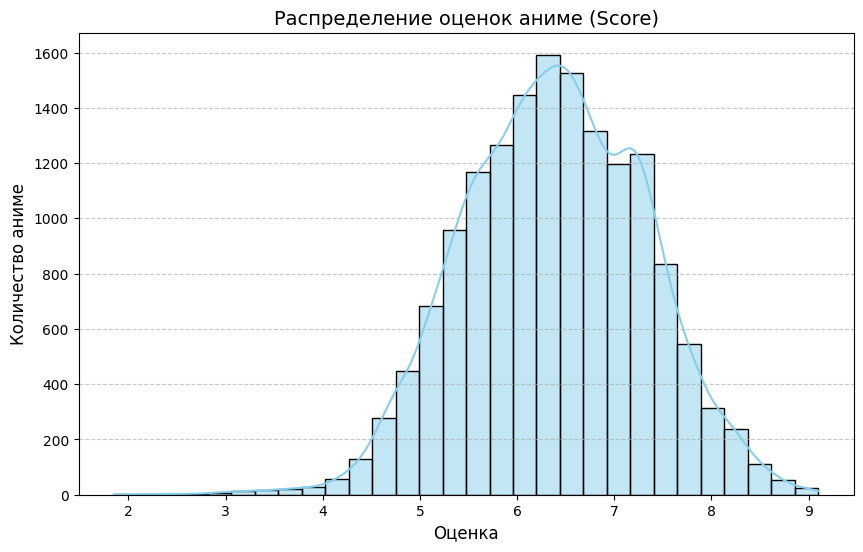

Статистика по Score:
count    15511.000000
mean         6.382000
std          0.930405
min          1.850000
25%          5.730000
50%          6.390000
75%          7.070000
max          9.100000
Name: Score, dtype: float64


In [804]:
# Гистограмма распределения оценок
plt.figure(figsize=(10, 6))
sns.histplot(data_raw['Score'], bins=30, kde=True, color='skyblue', edgecolor='black')
plt.title('Распределение оценок аниме (Score)', fontsize=14)
plt.xlabel('Оценка', fontsize=12)
plt.ylabel('Количество аниме', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Статистика
print("Статистика по Score:")
print(data_raw['Score'].describe())

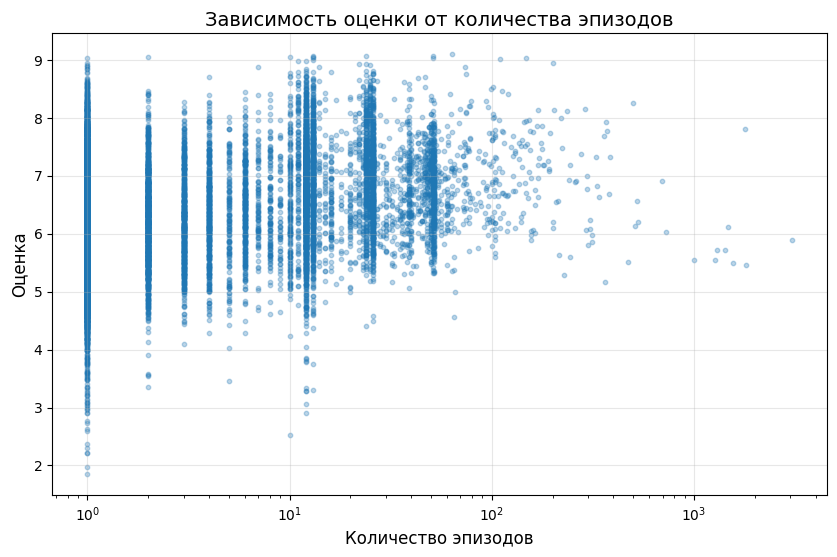

In [805]:
# Score vs Episodes
plt.figure(figsize=(10, 6))
plt.scatter(data_raw['Episodes'], data_raw['Score'], alpha=0.3, s=10)
plt.xscale('log')
plt.title('Зависимость оценки от количества эпизодов', fontsize=14)
plt.xlabel('Количество эпизодов', fontsize=12)
plt.ylabel('Оценка', fontsize=12)
plt.grid(alpha=0.3)
plt.show()

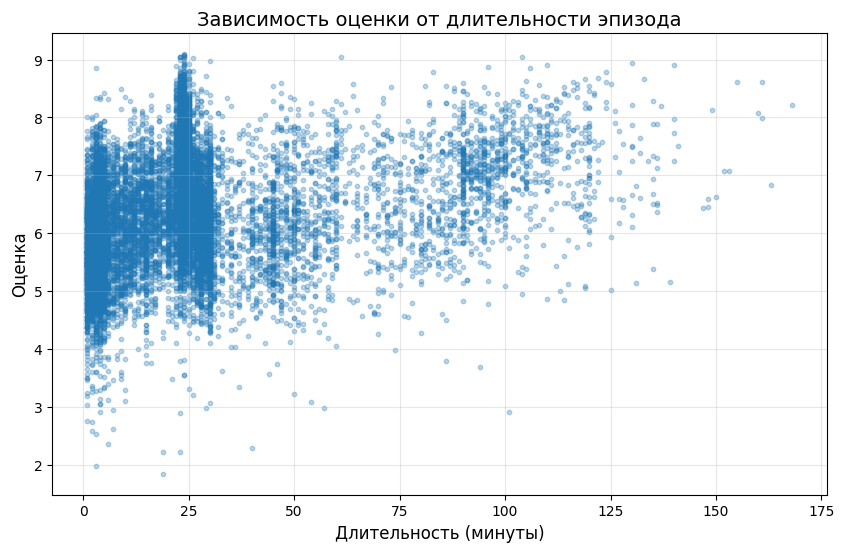

In [806]:
# Score vs Duration_Minutes
plt.figure(figsize=(10, 6))
plt.scatter(data_raw['Duration_Minutes'], data_raw['Score'], alpha=0.3, s=10)
plt.title('Зависимость оценки от длительности эпизода', fontsize=14)
plt.xlabel('Длительность (минуты)', fontsize=12)
plt.ylabel('Оценка', fontsize=12)
plt.grid(alpha=0.3)
plt.show()

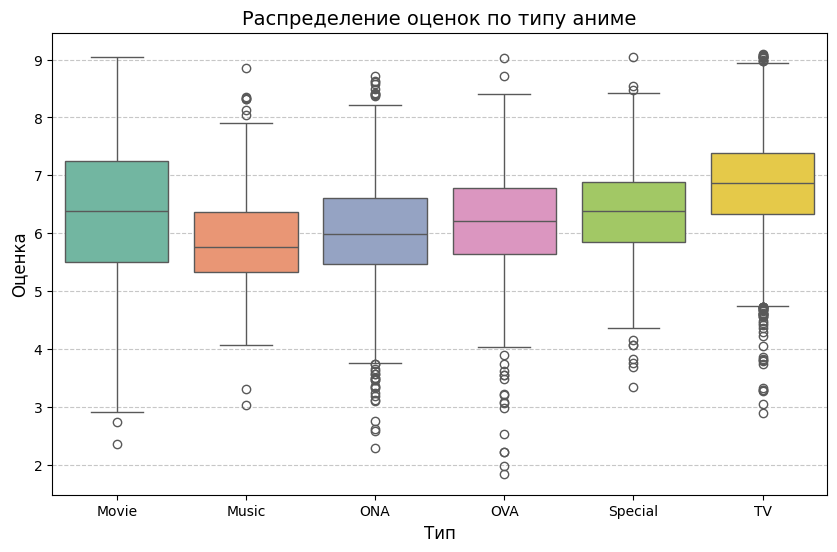

In [807]:
# Score по Type
plt.figure(figsize=(10, 6))
sns.boxplot(x='Type', y='Score', hue='Type', data=data_raw, palette='Set2', legend=False)
plt.title('Распределение оценок по типу аниме', fontsize=14)
plt.xlabel('Тип', fontsize=12)
plt.ylabel('Оценка', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

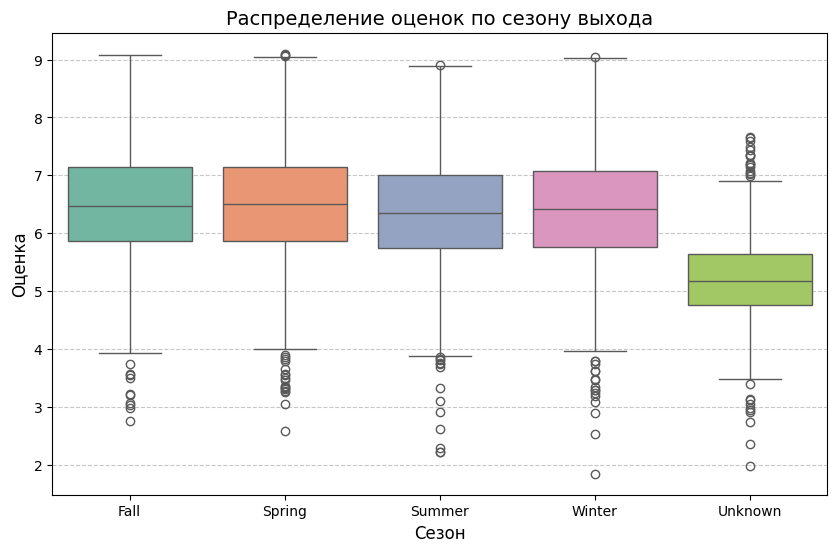

In [808]:
# Score по Season
plt.figure(figsize=(10, 6))
sns.boxplot(x='Season', y='Score', hue='Season', data=data_raw, palette='Set2', legend=False)
plt.title('Распределение оценок по сезону выхода', fontsize=14)
plt.xlabel('Сезон', fontsize=12)
plt.ylabel('Оценка', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

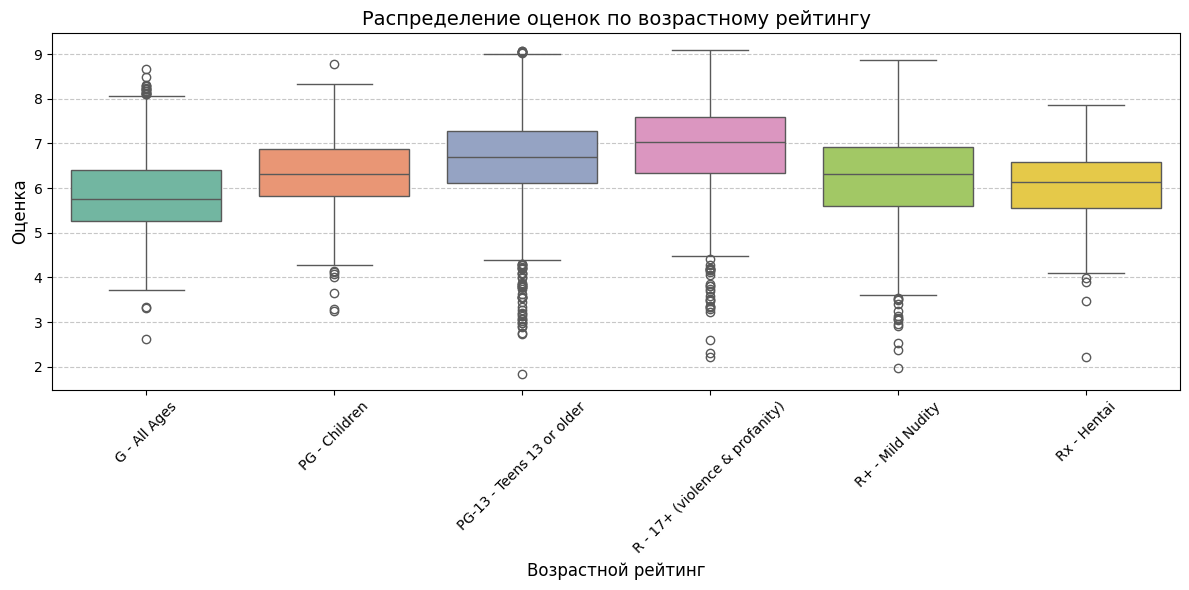

In [809]:
# Score по Rating
plt.figure(figsize=(12, 6))
sns.boxplot(x='Rating', y='Score', hue='Rating', data=data_raw, palette='Set2', legend=False)
plt.title('Распределение оценок по возрастному рейтингу', fontsize=14)
plt.xlabel('Возрастной рейтинг', fontsize=12)
plt.ylabel('Оценка', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#3. Разделение на train/test и предобработка

Разделим датасет на обучающую и тестовую выборки

In [810]:
X = data_raw.drop('Score', axis=1)
y = data_raw['Score']

In [811]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

N_train, d = X_train.shape
N_test,  d = X_test.shape

N_train, N_test, d

(11633, 3878, 26)

Заполнение пропущенных значений

In [812]:
median_episodes_by_type = X_train.groupby('Type')['Episodes'].median()
median_duration_by_type = X_train.groupby('Type')['Duration_Minutes'].median()

#print('медианное количество эпизодов по типам')
#print(median_episodes_by_type)
#print('медианное количество минут по типам')
#print(median_duration_by_type)

/tmp/ipykernel_981/1115195179.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  median_episodes_by_type = X_train.groupby('Type')['Episodes'].median()
/tmp/ipykernel_981/1115195179.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  median_duration_by_type = X_train.groupby('Type')['Duration_Minutes'].median()


In [813]:
X_train['Episodes'] = X_train['Episodes'].fillna(
    X_train['Type'].map(median_episodes_by_type).astype(float)
)
X_test['Episodes'] = X_test['Episodes'].fillna(
    X_test['Type'].map(median_episodes_by_type).astype(float)
)

X_train['Duration_Minutes'] = X_train['Duration_Minutes'].fillna(
    X_train['Type'].map(median_duration_by_type).astype(float)
)
X_test['Duration_Minutes'] = X_test['Duration_Minutes'].fillna(
    X_test['Type'].map(median_duration_by_type).astype(float)
)

print(f"Пропусков в Episodes осталось в X_train: {X_train['Episodes'].isna().sum()}")
print(f"Пропусков в Episodes осталось в X_test: {X_test['Episodes'].isna().sum()}")
print(f"Пропусков в Duration_Minutes осталось в X_train: {X_train['Duration_Minutes'].isna().sum()}")
print(f"Пропусков в Duration_Minutes осталось в X_test: {X_test['Duration_Minutes'].isna().sum()}")

Пропусков в Episodes осталось в X_train: 0
Пропусков в Episodes осталось в X_test: 0
Пропусков в Duration_Minutes осталось в X_train: 0
Пропусков в Duration_Minutes осталось в X_test: 0


Преобразование типов для обучения

In [814]:
# Кодирование категориальных признаков
X_train_encoded = pd.get_dummies(X_train, columns=['Type', 'Season', 'Source', 'Rating'], drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=['Type', 'Season', 'Source', 'Rating'], drop_first=True)

# выровняем столбцы в X_test по X_train на случай, если в тест попались редкие категории, которых не было в train
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

print(f"Размер X_train после кодирования: {X_train_encoded.shape}")
print(f"Размер X_test после кодирования: {X_test_encoded.shape}")

Размер X_train после кодирования: (11633, 49)
Размер X_test после кодирования: (3878, 49)


In [815]:
from sklearn.preprocessing import StandardScaler

numeric_features = ['Episodes', 'Duration_Minutes']

scaler = StandardScaler()

X_train_encoded[numeric_features] = scaler.fit_transform(X_train_encoded[numeric_features])
X_test_encoded[numeric_features] = scaler.transform(X_test_encoded[numeric_features])

print("Статистика числовых признаков после масштабирования:")
print(X_train_encoded[numeric_features].describe().round(2))

Статистика числовых признаков после масштабирования:
       Episodes  Duration_Minutes
count  11633.00          11633.00
mean       0.00             -0.00
std        1.00              1.00
min       -0.20             -0.97
25%       -0.20             -0.78
50%       -0.18             -0.10
75%        0.02              0.06
max       60.62              5.66


In [816]:
#X_test_encoded.dtypes

# 4. Обучение модели

##линейная регрессия

In [817]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_encoded, y_train)

LinearRegression()

In [818]:
y_train_predict = model.predict(X_train_encoded)
importances = pd.Series(model.coef_, index=X_train_encoded.columns).sort_values(ascending=False)
importances

,0
Rating_Rx - Hentai,0.602165
Rating_R - 17+ (violence & profanity),0.429847
Studio_Experienced,0.401673
Rating_PG-13 - Teens 13 or older,0.315501
Type_Music,0.247601
Drama,0.227557
Type_TV,0.212022
Mystery,0.204819
Producers_Experienced,0.200349
Source_Web manga,0.152964


In [819]:
model.coef_

array([ 0.01987956,  0.40167295,  0.20034916,  0.14431454,  0.02897776,
        0.05303077, -0.39023041,  0.05243216,  0.22755718, -0.18761841,
        0.13365577, -0.47661585, -0.43805204,  0.20481937,  0.09859954,
       -0.00494875,  0.10904335,  0.14336482,  0.15245681,  0.10983933,
       -0.00881802, -0.05254045,  0.24760089, -0.11100514, -0.17562635,
       -0.01043377,  0.21202222, -0.00641211, -0.07642868, -0.02746098,
       -0.41765879, -0.04276857, -0.22515783,  0.12507942,  0.12389687,
       -0.27356126, -0.43810553, -0.01812043, -0.25019013, -0.24505795,
       -0.3097056 , -0.35564545, -0.07037196,  0.1529639 ,  0.0749883 ,
        0.31550111,  0.42984706,  0.02464177,  0.60216538])

In [820]:
model.intercept_

np.float64(5.865149607234428)

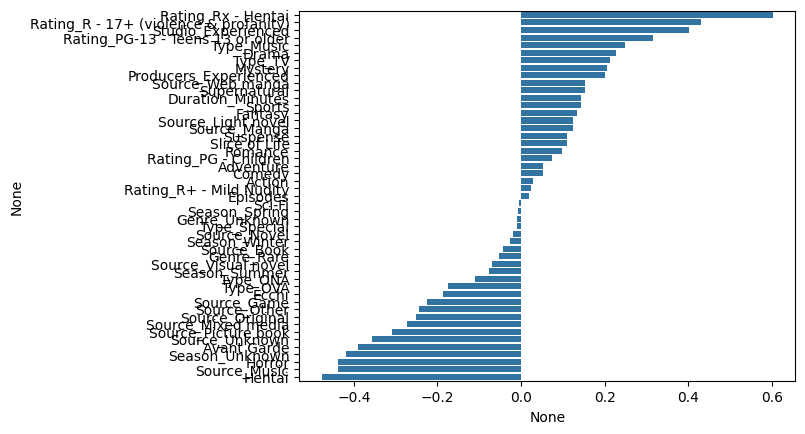

In [821]:
sns.barplot(y=importances.index, x=importances, orient="h")
pass

In [822]:
y_train_predict = model.predict(X_train_encoded)
y_test_predict  = model.predict(X_test_encoded)

In [823]:
from sklearn.metrics import mean_squared_error, r2_score

MSE_train = mean_squared_error(y_train, y_train_predict)
MSE_test  = mean_squared_error(y_test,  y_test_predict)
R2_train = r2_score(y_train, y_train_predict)
R2_test  = r2_score(y_test,  y_test_predict)

MSE_train, MSE_test, R2_train, R2_test

(0.4701726963031781,
 0.48605858491226583,
 0.4565945398358904,
 0.4391706949460822)

Модель объясняет около 45% дисперсии оценок зрителей. Для социально-культурных данных это неплохой результат, так как оценка сильно зависит от субъективных факторов и качества сценария, которых нет в датасете

In [824]:
RMSE_table = pd.DataFrame(columns=('train', 'test'))
RMSE_table.loc['Linear Regression, all features', :] = (RMSE_train, RMSE_test)
RMSE_table

,train,test
"Linear Regression, all features",0.652635,0.676729


In [825]:
R2_table = pd.DataFrame(columns=('train', 'test'))
R2_table.loc['Linear Regression, all features', :] = (R2_train, R2_test)
R2_table

,train,test
"Linear Regression, all features",0.456595,0.439171


##Метод к ближайших соседей

In [826]:
from sklearn.neighbors import KNeighborsRegressor

model = KNeighborsRegressor(n_neighbors=15) # по умолчанию n_neighbors=5
model.fit(X_train_encoded, y_train)

KNeighborsRegressor(n_neighbors=15)

In [827]:
y_train_predict = model.predict(X_train_encoded)
y_test_predict  = model.predict(X_test_encoded)

In [828]:
RMSE_train = mean_squared_error(y_train, y_train_predict)**.5
RMSE_test  = mean_squared_error(y_test,  y_test_predict)**.5
R2_train = r2_score(y_train, y_train_predict)
R2_test  = r2_score(y_test,  y_test_predict)

In [829]:
RMSE_table.loc['k Nearest Neighbours', :] = (RMSE_train, RMSE_test)
RMSE_table

,train,test
"Linear Regression, all features",0.652635,0.676729
k Nearest Neighbours,0.615529,0.669266


In [830]:
R2_table.loc['k Nearest Neighbours', :] = (R2_train, R2_test)
R2_table

,train,test
"Linear Regression, all features",0.456595,0.439171
k Nearest Neighbours,0.562112,0.48318


Подбор оптимального k

In [831]:
# Перебираем разные значения k
k_values = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50]

results = []

for k in k_values:
  model = KNeighborsRegressor(n_neighbors=k)
  model.fit(X_train_encoded, y_train)
  y_train_predict = model.predict(X_train_encoded)
  y_test_predict  = model.predict(X_test_encoded)
  RMSE_train = mean_squared_error(y_train, y_train_predict)**.5
  RMSE_test  = mean_squared_error(y_test,  y_test_predict)**.5
  R2_train = r2_score(y_train, y_train_predict)
  R2_test  = r2_score(y_test,  y_test_predict)
  print(f"k={k:3d} | RMSE_train={RMSE_train:.5f} | RMSE_test={RMSE_test:.5f} | R2_train={R2_train:.5f} | R2_test={R2_test:.5f}")
  results.append([k, RMSE_test, R2_test])



k=  1 | RMSE_train=0.21958 | RMSE_test=0.85379 | R2_train=0.94427 | R2_test=0.15890
k=  2 | RMSE_train=0.43783 | RMSE_test=0.75959 | R2_train=0.77844 | R2_test=0.33427
k=  3 | RMSE_train=0.49981 | RMSE_test=0.72690 | R2_train=0.71128 | R2_test=0.39033
k=  5 | RMSE_train=0.55246 | RMSE_test=0.69521 | R2_train=0.64725 | R2_test=0.44234
k=  7 | RMSE_train=0.57802 | RMSE_test=0.67861 | R2_train=0.61385 | R2_test=0.46864
k= 10 | RMSE_train=0.59503 | RMSE_test=0.67685 | R2_train=0.59080 | R2_test=0.47140
k= 15 | RMSE_train=0.61553 | RMSE_test=0.66927 | R2_train=0.56211 | R2_test=0.48318
k= 20 | RMSE_train=0.62645 | RMSE_test=0.66960 | R2_train=0.54643 | R2_test=0.48267
k= 30 | RMSE_train=0.63843 | RMSE_test=0.66925 | R2_train=0.52892 | R2_test=0.48320
k= 50 | RMSE_train=0.65264 | RMSE_test=0.67673 | R2_train=0.50773 | R2_test=0.47159


In [832]:
best_result_RMSE = min(results, key=lambda x: x[1])
best_result_R2 = max(results, key=lambda x: x[2])
print(f"Лучшее k по RMSE: {best_result_RMSE[0]} (RMSE_test={best_result_RMSE[1]:.5f}, R2_test={best_result_RMSE[2]:.5f})")
print(f"Лучшее k по R2: {best_result_R2[0]} (RMSE_test={best_result_R2[1]:.5f}, R2_test={best_result_R2[2]:.5f})")

Лучшее k по RMSE: 30 (RMSE_test=0.66925, R2_test=0.48320)
Лучшее k по R2: 30 (RMSE_test=0.66925, R2_test=0.48320)


перебор количества соседей, показал что на тестовой выборке лучший результат достигается при k = 30
значения совпали, что подтверждает устойчивость модели.

#Вывод

Был проведен анализ датасета рейтингов Аниме, с целью предсказать оценку будущего аниме, на основе его жанров, студии, категории, первоисточника и т.д.

Для этого была проведена работа по обработке датасета:
1. Отбор признаков: Мы исключили признаки, которые приводят к утечке данных (формируются после релиза): Members, Popularity, Favorites, Scored By, Rank. Также убрали Name, Synopsis (требуют сложной NLP-обработки) и Status (не несет полезной информации).
2. Работа с пропусками и редкими значениями: Значения "Unknown" и пропуски в столбцах Source, Rating, Studios и Producers были обработаны. Редкие категории (встречающиеся менее 20–100 раз) мы объединили в общую группу "Other" (или "Rare"), чтобы модель не переобучалась на шумах.
3. Обработка времени: Строковый признак Duration (например, "24 min") мы перевели в числовой формат Duration_Minutes.
4. Заполнение пропусков: Пропущенные значения в Episodes и Duration_Minutes заполнили медианными значениями, сгруппированными по типу аниме (Type). Явные выбросы (например, длительность более 180 минут для сериалов) были удалены.
5. Кодирование и масштабирование: Категориальные признаки (Type, Season, Source, Rating) закодировали с помощью One-Hot Encoding (get_dummies). Числовые признаки (Episodes, Duration_Minutes) нормализовали с помощью StandardScaler.

Было проведено моделирование методами линейной регрессии и К ближайших соседей. По итогу моделирования лучшим оказался метод 30 ближайших соседей, где метрика R2 на тесте составила около 0.48

Модель объясняет примерно 45–48% дисперсии зрительских оценок. Для задач прогнозирования в социально-культурной сфере это хороший результат. Оставшиеся 50% неопределенности закономерны, так как итоговая оценка аниме сильно зависит от субъективных факторов (качество сюжета, анимации, режиссуры), которых нет в нашем наборе данных. Тем не менее, модель успешно уловила базовые закономерности влияния объективных характеристик на успех аниме.